<a href="https://colab.research.google.com/github/sets1623/AI-SmartGrid-Forecasting/blob/main/GridMind_AI_Lite.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ⚡ GridMind AI Lite

### Electricity Demand Monitoring & Anomaly Detection
This prototype uses simulated data—not live grid measurements.

Average demand: 102.24 kW
Peak demand: 138.12 kW
Alert threshold: 132.67 kW
High-demand alerts: 1


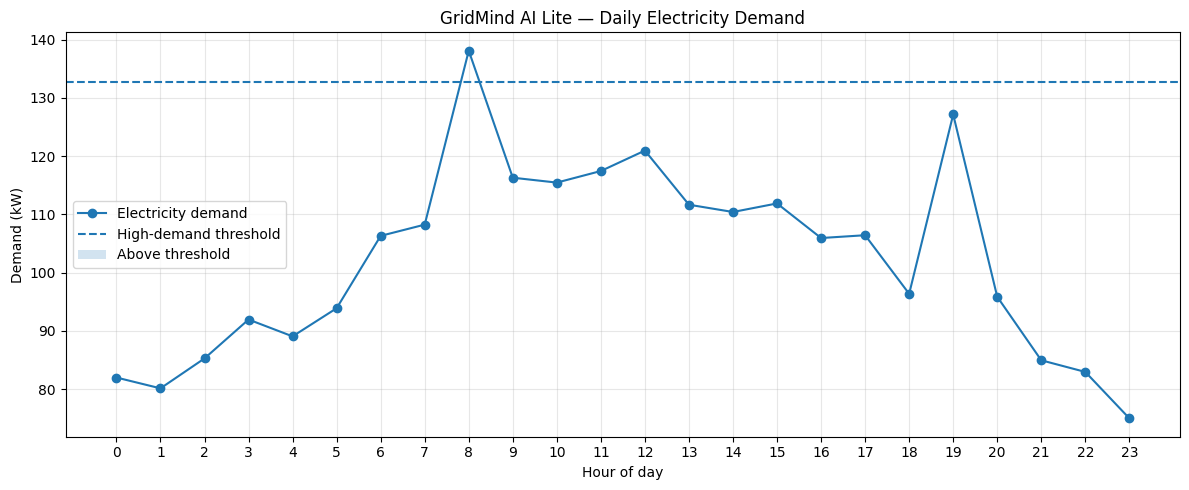

## 🚨 Demand Alerts

,Hour,Demand_kW,Status
8,8,138.12,High Demand Alert


## 💡 Recommendations

Review the flagged hours, check major loads, and consider shifting flexible consumption away from peak periods. Verify alerts against actual measurements before taking action.


## 📋 Complete Dataset

,Hour,Demand_kW,Status
0,0,81.99,Normal
1,1,80.13,Normal
2,2,85.27,Normal
3,3,91.95,Normal
4,4,89.06,Normal
5,5,93.89,Normal
6,6,106.32,Normal
7,7,108.25,Normal
8,8,138.12,High Demand Alert
9,9,116.31,Normal


In [1]:

# GRIDMIND AI LITE — Version 1
# Electricity Demand Monitoring & Anomaly Detection

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# 1. Generate sample electricity demand data
np.random.seed(42)

hours = np.arange(24)
normal_demand = 100 + 20 * np.sin(2 * np.pi * (hours - 6) / 24)
demand = normal_demand + np.random.normal(0, 4, 24)

# Add example unusual demand readings
demand[8] += 30
demand[19] += 38

df = pd.DataFrame({
    "Hour": hours,
    "Demand_kW": np.round(demand, 2)
})

# 2. Detect unusual readings using a transparent threshold
baseline = df["Demand_kW"].median()
threshold = baseline * 1.25
df["Status"] = np.where(
    df["Demand_kW"] > threshold,
    "High Demand Alert",
    "Normal"
)

# 3. Display project summary
display(Markdown("# ⚡ GridMind AI Lite"))
display(Markdown(
    "### Electricity Demand Monitoring & Anomaly Detection\n"
    "This prototype uses simulated data—not live grid measurements."
))

print(f"Average demand: {df['Demand_kW'].mean():.2f} kW")
print(f"Peak demand: {df['Demand_kW'].max():.2f} kW")
print(f"Alert threshold: {threshold:.2f} kW")
print(f"High-demand alerts: {(df['Status'] == 'High Demand Alert').sum()}")

# 4. Plot the demand profile
plt.figure(figsize=(12, 5))
plt.plot(df["Hour"], df["Demand_kW"], marker="o",
         label="Electricity demand")
plt.axhline(threshold, linestyle="--",
            label="High-demand threshold")
plt.fill_between(
    df["Hour"], threshold, df["Demand_kW"],
    where=df["Demand_kW"] > threshold,
    alpha=0.2, label="Above threshold"
)
plt.xticks(hours)
plt.xlabel("Hour of day")
plt.ylabel("Demand (kW)")
plt.title("GridMind AI Lite — Daily Electricity Demand")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# 5. Show alerts and recommendations
alerts = df[df["Status"] == "High Demand Alert"]

display(Markdown("## 🚨 Demand Alerts"))
if alerts.empty:
    print("No readings exceeded the configured threshold.")
else:
    display(alerts)

display(Markdown("## 💡 Recommendations"))
if alerts.empty:
    print("Continue monitoring demand and review peak periods.")
else:
    print(
        "Review the flagged hours, check major loads, and consider "
        "shifting flexible consumption away from peak periods. "
        "Verify alerts against actual measurements before taking action."
    )

display(Markdown("## 📋 Complete Dataset"))
display(df)


In [2]:

# GRIDMIND AI LITE — STEP 3
# Upload and analyze real or sample electricity-demand data

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
from IPython.display import display, Markdown

display(Markdown("# ⚡ GridMind AI Lite — Data Analyzer"))
display(Markdown(
    "Upload a CSV containing electricity-demand readings. "
    "If you don't have a file, generate sample data below."
))

# Generate a downloadable sample dataset
np.random.seed(42)
hours = np.arange(24)
baseline_demand = 100 + 20 * np.sin(
    2 * np.pi * (hours - 6) / 24
)
sample_demand = baseline_demand + np.random.normal(0, 4, 24)
sample_demand[8] += 30
sample_demand[19] += 38

sample_df = pd.DataFrame({
    "Hour": hours,
    "Demand_kW": np.round(sample_demand, 2)
})

sample_df.to_csv("gridmind_sample.csv", index=False)

print("Sample CSV created: gridmind_sample.csv")
display(sample_df.head())

# Upload your own CSV or use the sample dataset
choice = input(
    "Type SAMPLE to use sample data, or UPLOAD to upload your CSV: "
).strip().upper()

if choice == "UPLOAD":
    uploaded = files.upload()

    if not uploaded:
        raise ValueError("No file uploaded. Run this cell again.")

    filename = next(iter(uploaded))
    df = pd.read_csv(filename)

elif choice == "SAMPLE":
    df = sample_df.copy()

else:
    raise ValueError("Please enter SAMPLE or UPLOAD.")

# Validate required data
if "Demand_kW" not in df.columns:
    raise ValueError(
        "CSV must contain a column named Demand_kW. "
        "Optional column: Hour."
    )

df["Demand_kW"] = pd.to_numeric(
    df["Demand_kW"], errors="coerce"
)
df = df.dropna(subset=["Demand_kW"]).reset_index(drop=True)

if df.empty:
    raise ValueError("No valid numeric demand readings found.")

if "Hour" not in df.columns:
    df["Hour"] = np.arange(len(df))

# Configurable anomaly threshold
baseline = df["Demand_kW"].median()
threshold = baseline * 1.25

df["Status"] = np.where(
    df["Demand_kW"] > threshold,
    "High Demand Alert",
    "Normal"
)

# Summary metrics
display(Markdown("## 📊 Analysis Results"))
print(f"Valid readings: {len(df)}")
print(f"Average demand: {df['Demand_kW'].mean():.2f} kW")
print(f"Peak demand: {df['Demand_kW'].max():.2f} kW")
print(f"Minimum demand: {df['Demand_kW'].min():.2f} kW")
print(f"Median demand: {baseline:.2f} kW")
print(f"Alert threshold: {threshold:.2f} kW")
print(f"Alerts detected: {(df['Status'] != 'Normal').sum()}")

# Demand visualization
plt.figure(figsize=(12, 5))
plt.plot(df["Hour"], df["Demand_kW"], marker="o",
         label="Demand")
plt.axhline(threshold, linestyle="--",
            label="Alert threshold")
plt.scatter(
    df.loc[df["Status"] != "Normal", "Hour"],
    df.loc[df["Status"] != "Normal", "Demand_kW"],
    marker="x", s=100, label="Flagged readings"
)
plt.xlabel("Hour / Reading Index")
plt.ylabel("Electricity Demand (kW)")
plt.title("GridMind AI Lite — Demand Analysis")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Alerts and recommendations
display(Markdown("## 🚨 Flagged Readings"))
alerts = df[df["Status"] != "Normal"]
display(alerts if not alerts.empty else
        pd.DataFrame({"Message": ["No readings exceeded the threshold."]}))

display(Markdown("## 💡 Recommendations"))
if alerts.empty:
    print("Continue monitoring demand and review peak periods.")
else:
    print(
        "Inspect the flagged readings and check which loads were active. "
        "Consider scheduling flexible loads outside peak periods. "
        "Confirm alerts using actual measurements before taking action."
    )

display(Markdown("## 📋 Analyzed Dataset"))
display(df)

# Download analyzed results
df.to_csv("gridmind_analysis_results.csv", index=False)
print("Results saved as gridmind_analysis_results.csv")


# ⚡ GridMind AI Lite — Data Analyzer

Upload a CSV containing electricity-demand readings. If you don't have a file, generate sample data below.

Sample CSV created: gridmind_sample.csv


,Hour,Demand_kW
0,0,81.99
1,1,80.13
2,2,85.27
3,3,91.95
4,4,89.06


KeyboardInterrupt: Interrupted by user

# ⚡ GridMind AI Lite

## 📊 Electricity Demand Analysis

Average demand: 102.24 kW
Peak demand: 138.12 kW
Alert threshold: 132.67 kW
Alerts: 1


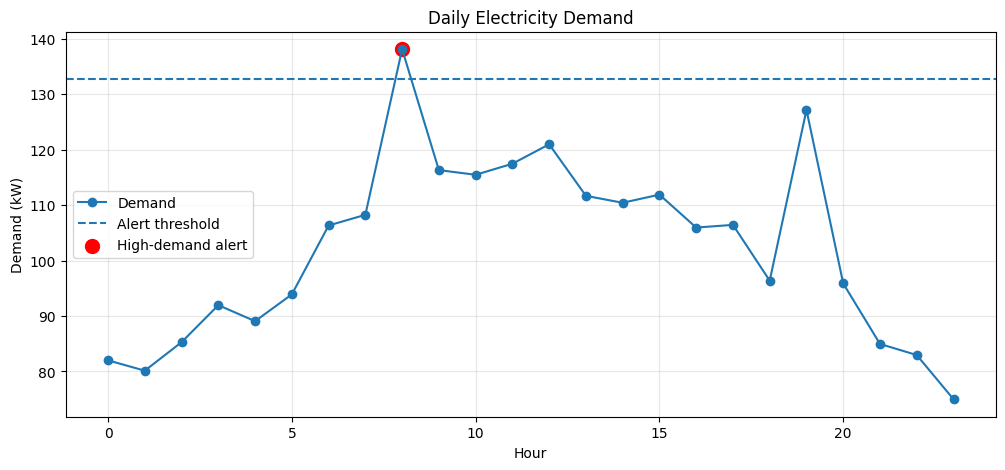

## 🚨 Alerts

,Hour,Demand_kW,Status
8,8,138.12,High Demand Alert


## 📋 Complete Dataset

,Hour,Demand_kW,Status
0,0,81.99,Normal
1,1,80.13,Normal
2,2,85.27,Normal
3,3,91.95,Normal
4,4,89.06,Normal
5,5,93.89,Normal
6,6,106.32,Normal
7,7,108.25,Normal
8,8,138.12,High Demand Alert
9,9,116.31,Normal


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from google.colab import files

# Generate the sample CSV automatically
np.random.seed(42)
hours = np.arange(24)
baseline = 100 + 20 * np.sin(2 * np.pi * (hours - 6) / 24)
demand = baseline + np.random.normal(0, 4, 24)
demand[8] += 30
demand[19] += 38

sample_df = pd.DataFrame({
    "Hour": hours,
    "Demand_kW": np.round(demand, 2)
})

sample_df.to_csv("gridmind_sample.csv", index=False)

# Automatically load the generated CSV
df = pd.read_csv("gridmind_sample.csv")

# Detect unusually high demand
threshold = df["Demand_kW"].median() * 1.25
df["Status"] = np.where(
    df["Demand_kW"] > threshold,
    "High Demand Alert",
    "Normal"
)

# Display dashboard
display(Markdown("# ⚡ GridMind AI Lite"))
display(Markdown("## 📊 Electricity Demand Analysis"))

print(f"Average demand: {df['Demand_kW'].mean():.2f} kW")
print(f"Peak demand: {df['Demand_kW'].max():.2f} kW")
print(f"Alert threshold: {threshold:.2f} kW")
print(f"Alerts: {(df['Status'] != 'Normal').sum()}")

plt.figure(figsize=(12, 5))
plt.plot(df["Hour"], df["Demand_kW"], marker="o", label="Demand")
plt.axhline(threshold, linestyle="--", label="Alert threshold")

alerts = df[df["Status"] != "Normal"]
plt.scatter(
    alerts["Hour"], alerts["Demand_kW"],
    color="red", s=100, label="High-demand alert"
)

plt.xlabel("Hour")
plt.ylabel("Demand (kW)")
plt.title("Daily Electricity Demand")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

display(Markdown("## 🚨 Alerts"))
display(alerts)

display(Markdown("## 📋 Complete Dataset"))
display(df)

# Download the generated CSV to your computer if needed
files.download("gridmind_sample.csv")


In [4]:

# GRIDMIND AI LITE — STEP 4
# Interactive Electricity Monitoring Dashboard

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets

from IPython.display import display, clear_output, Markdown
from google.colab import files

# Use the dataset created in Step 3
if "df" not in globals() or "Demand_kW" not in df.columns:
    df = pd.read_csv("gridmind_sample.csv")

data = df.copy().reset_index(drop=True)
data["Demand_kW"] = pd.to_numeric(
    data["Demand_kW"], errors="coerce"
)
data = data.dropna(subset=["Demand_kW"]).reset_index(drop=True)

if data.empty:
    raise ValueError("No valid electricity-demand readings found.")

if "Hour" not in data.columns:
    data["Hour"] = np.arange(len(data))

data["Hour"] = data["Hour"].astype(str)

# Dashboard controls
threshold_slider = widgets.FloatSlider(
    value=1.25,
    min=1.05,
    max=1.75,
    step=0.05,
    description="Threshold:",
    readout_format=".2f",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="80%")
)

output = widgets.Output()

def render_dashboard(multiplier):
    with output:
        clear_output(wait=True)

        baseline = data["Demand_kW"].median()
        threshold = baseline * multiplier

        results = data.copy()
        results["Status"] = np.where(
            results["Demand_kW"] > threshold,
            "High Demand Alert",
            "Normal"
        )

        alerts = results[
            results["Status"] == "High Demand Alert"
        ]

        # Header and key metrics
        display(Markdown(
            "# ⚡ GridMind AI Lite\n"
            "### Interactive Electricity Demand Dashboard\n"
            "_Demonstration using sample or uploaded readings._"
        ))

        print(f"Readings analyzed: {len(results)}")
        print(f"Average demand: {results['Demand_kW'].mean():.2f} kW")
        print(f"Peak demand: {results['Demand_kW'].max():.2f} kW")
        print(f"Alert threshold: {threshold:.2f} kW")
        print(f"Flagged readings: {len(alerts)}")

        # Demand chart
        x = np.arange(len(results))
        y = results["Demand_kW"].to_numpy()

        plt.figure(figsize=(12, 5))
        plt.plot(x, y, marker="o", label="Demand")
        plt.axhline(
            threshold, linestyle="--",
            label="Alert threshold"
        )

        if not alerts.empty:
            alert_indices = results.index[
                results["Status"] == "High Demand Alert"
            ].to_numpy()

            plt.scatter(
                alert_indices,
                results.loc[alert_indices, "Demand_kW"],
                marker="x", s=120,
                label="Flagged readings"
            )

        plt.xticks(x, results["Hour"], rotation=45)
        plt.xlabel("Hour / Reading label")
        plt.ylabel("Demand (kW)")
        plt.title("Electricity Demand Profile")
        plt.grid(True, alpha=0.3)
        plt.legend()
        plt.tight_layout()
        plt.show()

        # Alert table
        display(Markdown("## 🚨 Demand Alerts"))
        if alerts.empty:
            print("No readings exceed the selected threshold.")
        else:
            display(alerts)

        # Recommendations
        display(Markdown("## 💡 Recommendations"))
        if alerts.empty:
            print(
                "Continue monitoring demand and review "
                "peak usage periods."
            )
        else:
            print(
                "Review flagged readings and identify the loads "
                "operating during those periods. Consider shifting "
                "flexible loads away from peak demand. Verify readings "
                "before making operational decisions."
            )

        # Export analyzed results
        results.to_csv(
            "gridmind_analysis_results.csv", index=False
        )
        display(Markdown(
            "## 📁 Export\n"
            "Your analyzed results are ready to download."
        ))

# Refresh dashboard when slider changes
def update_dashboard(change):
    render_dashboard(change["new"])

threshold_slider.observe(update_dashboard, names="value")

display(Markdown("## Dashboard Controls"))
display(threshold_slider)
display(output)

render_dashboard(threshold_slider.value)


## Dashboard Controls

FloatSlider(value=1.25, description='Threshold:', layout=Layout(width='80%'), max=1.75, min=1.05, step=0.05, s…

Output()

In [5]:
files.download("gridmind_analysis_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# 🤖 GridMind AI — Anomaly Detection

Algorithm: Isolation Forest
Readings analyzed: 24
Potential anomalies detected: 3


,Hour,Demand_kW,Demand_Change,AI_Alert
8,8,138.12,29.87,Potential Anomaly
19,19,127.17,30.80,Potential Anomaly
20,20,95.86,-31.31,Potential Anomaly


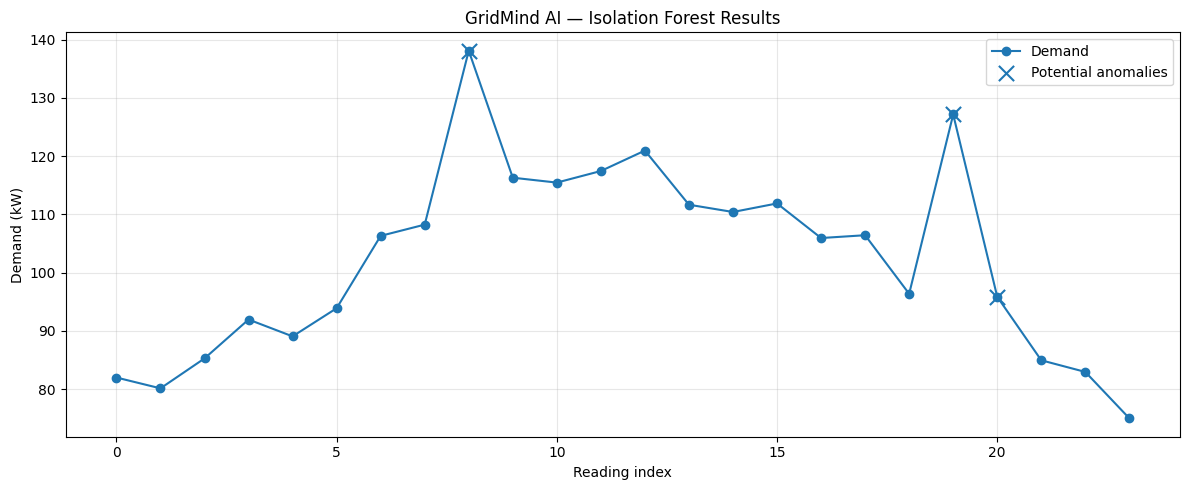

Saved: gridmind_ai_results.csv


In [6]:

# GRIDMIND AI LITE — STEP 5
# Machine-learning anomaly detection

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import IsolationForest
from IPython.display import display, Markdown

# Load the existing dataset
if "data" in globals() and "Demand_kW" in data.columns:
    ml_data = data.copy().reset_index(drop=True)
elif "df" in globals() and "Demand_kW" in df.columns:
    ml_data = df.copy().reset_index(drop=True)
else:
    ml_data = pd.read_csv("gridmind_sample.csv")

ml_data["Demand_kW"] = pd.to_numeric(
    ml_data["Demand_kW"], errors="coerce"
)
ml_data = ml_data.dropna(subset=["Demand_kW"]).reset_index(drop=True)

if len(ml_data) < 5:
    raise ValueError("At least five valid readings are required.")

# Model input: demand and change from the previous reading
ml_data["Demand_Change"] = ml_data["Demand_kW"].diff().fillna(0)

features = ml_data[["Demand_kW", "Demand_Change"]]

# Train the unsupervised anomaly detector
model = IsolationForest(
    n_estimators=200,
    contamination=0.10,
    random_state=42
)

ml_data["Model_Result"] = model.fit_predict(features)
ml_data["AI_Alert"] = np.where(
    ml_data["Model_Result"] == -1,
    "Potential Anomaly",
    "Normal"
)

# Display results
display(Markdown("# 🤖 GridMind AI — Anomaly Detection"))

print("Algorithm: Isolation Forest")
print(f"Readings analyzed: {len(ml_data)}")
print(
    "Potential anomalies detected:",
    (ml_data["AI_Alert"] == "Potential Anomaly").sum()
)

display(
    ml_data.loc[
        ml_data["AI_Alert"] == "Potential Anomaly",
        ["Hour", "Demand_kW", "Demand_Change", "AI_Alert"]
    ]
)

# Visualize flagged points
plt.figure(figsize=(12, 5))

normal = ml_data["AI_Alert"] == "Normal"
anomaly = ~normal

plt.plot(
    ml_data.index, ml_data["Demand_kW"],
    marker="o", label="Demand"
)

plt.scatter(
    ml_data.index[anomaly],
    ml_data.loc[anomaly, "Demand_kW"],
    marker="x", s=120, label="Potential anomalies"
)

plt.xlabel("Reading index")
plt.ylabel("Demand (kW)")
plt.title("GridMind AI — Isolation Forest Results")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Export results
ml_data.to_csv("gridmind_ai_results.csv", index=False)
print("Saved: gridmind_ai_results.csv")


In [7]:

from pathlib import Path
import zipfile

project = Path("GridMind_AI_Lite")
project.mkdir(exist_ok=True)

documents = {
    "scope.md": """# GridMind AI Lite — Project Scope

## Problem
Electricity users may struggle to identify unusual demand patterns
from hourly consumption readings.

## Goal
Build a browser-accessible prototype that analyzes electricity demand,
visualizes patterns, and flags potentially unusual readings.

## Target Users
- Electrical engineering students
- Energy analysts exploring sample datasets
- Learners experimenting with anomaly detection

## Core Features
1. Load electricity demand data from CSV.
2. Calculate basic demand statistics.
3. Visualize the demand profile.
4. Flag unusual readings with a configurable threshold.
5. Apply an experimental Isolation Forest detector.
6. Export analysis results.

## Out of Scope
- Live grid integration
- Automatic switching or control of electrical equipment
- Guaranteed fault detection
- Production-grade cybersecurity or safety certification

## Success Criteria
- The notebook runs in Google Colab.
- A sample CSV can be analyzed end to end.
- Charts, summary metrics, and alerts are displayed.
- Results can be exported to CSV.
""",
    "prd.md": """# GridMind AI Lite — Product Requirements

## Product Summary
GridMind AI Lite is an educational electricity-demand analysis
prototype combining visual analytics with experimental anomaly detection.

## User Need
Users need a simple way to inspect demand readings, understand peak
periods, and identify measurements that may deserve further review.

## User Stories
- As a user, I can analyze a CSV of demand readings.
- As a user, I can view average and peak demand.
- As a user, I can visualize readings over time.
- As a user, I can see threshold-based alerts.
- As a user, I can inspect machine-learning anomaly flags.
- As a user, I can export analysis results.

## Functional Requirements
- Accept numeric Demand_kW values.
- Support an optional Hour column.
- Handle missing or invalid demand readings.
- Display demand charts and summary statistics.
- Export results to CSV.

## Non-Functional Requirements
- Run in Google Colab without local software installation.
- Provide understandable outputs and error messages.
- Clearly label simulated data and experimental predictions.

## Limitations
Isolation Forest results are not confirmed electrical faults.
The prototype is not connected to a live grid and must not be used
for operational protection decisions.
""",
    "spec.md": """# GridMind AI Lite — Technical Specification

## Environment
- Google Colab
- Python
- pandas and NumPy
- Matplotlib
- scikit-learn
- ipywidgets

## Input Data
CSV file with:
- Demand_kW: numeric electricity demand in kilowatts
- Hour: optional reading label

## Processing Pipeline
1. Load CSV or generate demonstration data.
2. Convert demand readings to numeric values.
3. Remove invalid demand entries.
4. Calculate mean, median, minimum, and maximum.
5. Flag demand above a configurable multiple of the median.
6. Fit an Isolation Forest model to demand and demand-change features.
7. Display charts and flagged rows.
8. Export results as CSV.

## Model Configuration
- Algorithm: Isolation Forest
- Estimators: 200
- Contamination: 0.10
- Random seed: 42

## Validation
- Test with the included synthetic dataset.
- Check that charts and summary metrics appear.
- Verify that exported CSV files contain analysis columns.
- Review model flags manually.

## Known Limitations
The demonstration dataset is small and simulated. Results are not
validated against real-world fault labels or operational grid data.
""",
}

for filename, content in documents.items():
    (project / filename).write_text(content, encoding="utf-8")

# Package all three files
zip_path = "GridMind_AI_Lite_Planning_Docs.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for filename in documents:
        z.write(project / filename, arcname=filename)

print("Created project planning documents:")
for filename in documents:
    print("✓", project / filename)

print(f"\nZIP created: {zip_path}")


Created project planning documents:
✓ GridMind_AI_Lite/scope.md
✓ GridMind_AI_Lite/prd.md
✓ GridMind_AI_Lite/spec.md

ZIP created: GridMind_AI_Lite_Planning_Docs.zip


In [8]:
from google.colab import files
files.download("GridMind_AI_Lite_Planning_Docs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>